# Petit tour des salaires

On explore uniquement les données du secteur privé : salaires par secteur, sexe, taille d’entreprise et temps de travail, puis quelques indicateurs d’inégalités et leur évolution.

**Avant de commencer :** lance d’abord `Nettoyage_donnees.ipynb`. Ce notebook lit les CSV dans `Data nettoyees/` et ne modifie aucun fichier.

## 1. On charge les données

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def trouver_racine_projet():
    courant = Path.cwd().resolve()
    for dossier in (courant, *courant.parents):
        if (dossier / 'Data nettoyees').is_dir():
            return dossier
    raise FileNotFoundError(
        'Dossier « Data nettoyees » introuvable. Lance d’abord le notebook de nettoyage.'
    )


RACINE = trouver_racine_projet()
DOSSIER_DONNEES = RACINE / 'Data nettoyees'
CHEMIN_PRIVE = DOSSIER_DONNEES / 'DS_DERA_PRIVE_SERIES_LONGUES_data_nettoye.csv'
if not CHEMIN_PRIVE.is_file():
    raise FileNotFoundError(
        f'Fichier privé nettoyé absent : {CHEMIN_PRIVE}. '
        'Lance d’abord le notebook de nettoyage.'
    )

prive = pd.read_csv(CHEMIN_PRIVE, sep=';', encoding='utf-8-sig')
print(f"Données privées : {len(prive):,} lignes, de {prive['annee'].min()} à {prive['annee'].max()}.")

SALAIRE = 'Salaire net moyen mensuel (Euros constants)'
MOYENNE = 'Ensemble'
P10 = '10e centile (D1 - 10% gagnent moins)'
P25 = '1er quartile (Q1 - 25% gagnent moins)'
P50 = 'Médiane (50% gagnent moins/plus)'
P90 = '90e centile (D9 - 10% gagnent plus)'
P95 = '95e centile (Top 5%)'
P99 = '99e centile (Top 1%)'

VALEURS_ENSEMBLE = {
    'secteur_activite': 'Ensemble des secteurs',
    'tranche_age': 'Ensemble',
    'taille_entreprise': 'Ensemble',
    'categorie_socio_prof': 'Ensemble',
    'sexe': 'Ensemble',
    'temps_travail': 'Ensemble',
}


def garder_ensemble_des_autres_dimensions(df, dimension=None):
    resultat = df.copy()
    for colonne, modalite in VALEURS_ENSEMBLE.items():
        if colonne in resultat.columns and colonne != dimension:
            resultat = resultat[resultat[colonne].eq(modalite)]
    return resultat


def extraire_salaire(df, quantiles, dimension=None):
    resultat = garder_ensemble_des_autres_dimensions(df, dimension)
    resultat = resultat[
        resultat['indicateur'].eq(SALAIRE)
        & resultat['unite'].eq('Euros constants')
        & resultat['centile_salaire'].isin(quantiles)
    ].copy()
    cles = ['annee', 'centile_salaire']
    if dimension:
        cles.insert(0, dimension)
    if resultat.duplicated(cles).any():
        raise ValueError(f'Plusieurs valeurs pour les mêmes clés : {cles}')
    return resultat


def serie_quantile(df, quantile, etiquette):
    table = extraire_salaire(df, [quantile])
    table = table[['annee', 'valeur']].rename(columns={'valeur': 'Salaire (€ constants)'})
    table['Série'] = etiquette
    return table


def bilan_evolution(series):
    resultats = []
    for nom, groupe in series.groupby('Série'):
        groupe = groupe.sort_values('annee')
        debut, fin = groupe.iloc[0], groupe.iloc[-1]
        resultats.append(
            {
                'Série': nom,
                'Période': f"{int(debut['annee'])}–{int(fin['annee'])}",
                'Variation (%)': (
                    fin['Salaire (€ constants)'] / debut['Salaire (€ constants)'] - 1
                ) * 100,
            }
        )
    return pd.DataFrame(resultats).set_index('Série')

Données privées : 14,768 lignes, de 1951 à 2024.


## 2. Écart de salaire moyen entre hommes et femmes

On mesure l’écart avec **(salaire homme − salaire femme) / salaire homme × 100**. Par exemple, 10 % signifie que le salaire moyen des femmes est inférieur de 10 % à celui des hommes. On garde le secteur, l’âge, la taille d’entreprise, la catégorie socio-professionnelle et le temps de travail sur « Ensemble ».

sexe,Homme,Femme,Écart H-F (% du salaire homme)
annee,,,
2015,"2,885","2,367",18.0%
2016,"2,892","2,385",17.5%
2017,"2,906","2,422",16.7%
2018,"2,911","2,437",16.3%
2019,"2,930","2,478",15.4%
2020,"3,010","2,569",14.7%
2021,"2,950","2,525",14.4%
2022,"2,906","2,505",13.8%
2023,"2,872","2,490",13.3%


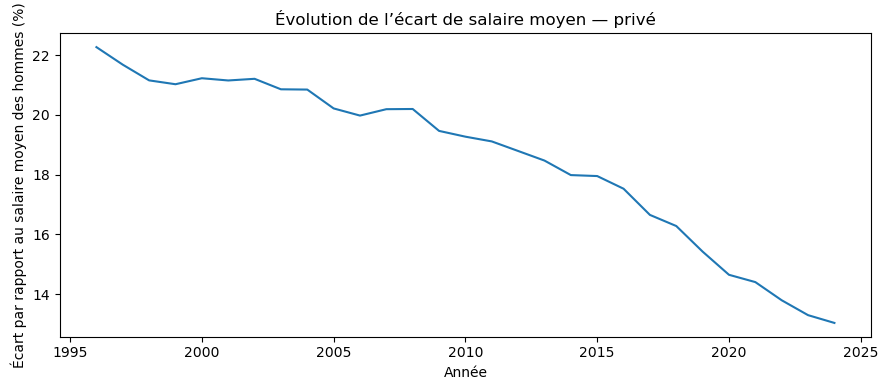

Écart : 22.3% en 1996, puis 13.0% en 2024.


In [2]:
salaires_sexe = extraire_salaire(prive, [MOYENNE], 'sexe')
moyenne_sexe = salaires_sexe.pivot(
    index='annee', columns='sexe', values='valeur'
).dropna(subset=['Homme', 'Femme'])
moyenne_sexe['Écart H-F (% du salaire homme)'] = (
    (moyenne_sexe['Homme'] - moyenne_sexe['Femme']) / moyenne_sexe['Homme'] * 100
)

display(
    moyenne_sexe[['Homme', 'Femme', 'Écart H-F (% du salaire homme)']]
    .tail(10)
    .style.format({'Homme': '{:,.0f}', 'Femme': '{:,.0f}', 'Écart H-F (% du salaire homme)': '{:.1f}%'})
)

moyenne_sexe['Écart H-F (% du salaire homme)'].plot(figsize=(9, 4))
plt.title('Évolution de l’écart de salaire moyen — privé')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()

print(
    f"Écart : {moyenne_sexe['Écart H-F (% du salaire homme)'].iloc[0]:.1f}% "
    f"en {moyenne_sexe.index.min()}, puis "
    f"{moyenne_sexe['Écart H-F (% du salaire homme)'].iloc[-1]:.1f}% "
    f"en {moyenne_sexe.index.max()}."
)

## 3. Évolution de l’écart salarial par grande catégorie

On reprend le même écart que dans la section suivante, **(salaire moyen homme − salaire moyen femme) / salaire moyen homme × 100**, mais en regroupant les secteurs NAF. Pour chaque catégorie et chaque année, on fait la moyenne simple des salaires moyens des secteurs qui la composent (les données ne donnent pas ici de pondération par nombre de salariés).

| Catégorie | Secteurs inclus | Fréquence cumulée |
|---|---|---:|
| Industrie et Énergie | Industries extractives/énergie/eau/déchets; alimentation/boissons/tabac; cokéfaction-raffinage; produits informatiques/électroniques/machines; matériels de transport; autres industries manufacturières | 1 548 (6 × 258) |
| Construction | Construction | 258 |
| Services marchands | Commerce; transports; hébergement-restauration; information-communication; finance-assurance; immobilier; services aux entreprises (M_N) | 1 806 (7 × 258) |
| Services non marchands et aux ménages | Administration publique/enseignement/santé/action sociale; arts, loisirs et autres services | 516 (2 × 258) |

Les autres dimensions (âge, taille, catégorie socio-professionnelle et temps de travail) restent sur « Ensemble ».

categorie_regroupee,Construction,Industrie et Énergie,Services marchands,Services non marchands et aux ménages
annee,,,,
2015,-1.3%,13.4%,19.9%,20.1%
2016,-1.1%,12.8%,19.4%,18.8%
2017,-1.6%,11.7%,18.9%,19.0%
2018,-2.1%,11.8%,18.5%,18.5%
2019,-2.2%,11.0%,17.4%,19.2%
2020,-1.9%,10.5%,17.0%,16.3%
2021,-1.7%,10.4%,17.1%,17.6%
2022,-2.0%,10.0%,16.7%,17.1%
2023,-2.1%,9.6%,16.0%,16.1%


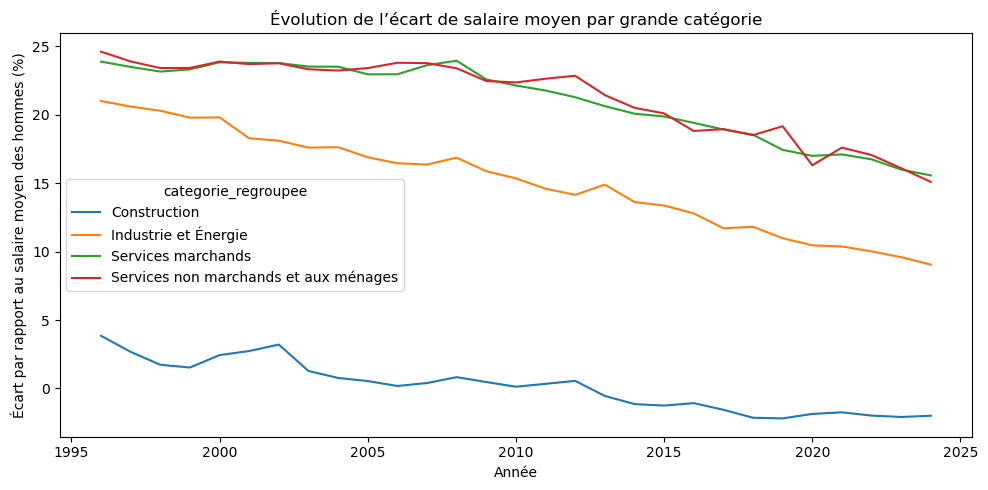

,Début (%),Fin (%),Évolution (points)
categorie_regroupee,,,
Construction,3.8%,-2.0%,-5.8
Industrie et Énergie,21.0%,9.1%,-12.0
Services marchands,23.9%,15.6%,-8.3
Services non marchands et aux ménages,24.6%,15.1%,-9.5


In [3]:
CATEGORIES_SECTEURS = {
    'Industrie et Énergie': [
        'Industries extractives, énergie, eau, déchets (B_D_E)',
        'Fabrication d’aliments, boissons et tabac (C10T12)',
        'Cokéfaction et raffinage (C19)',
        'Fabrication de produits informatiques, électroniques et machines (C26T28)',
        'Fabrication de matériels de transport (C29_30)',
        'Autres industries manufacturières (C_OTH)',
    ],
    'Construction': ['Construction'],
    'Services marchands': [
        'Commerce ; réparation d’automobiles et de motocycles',
        'Transports et entreposage',
        'Hébergement et restauration',
        'Information et communication',
        'Activités financières et d’assurance',
        'Activités immobilières',
        'Activités spécialisées, scientifiques, techniques et services support (M_N)',
    ],
    'Services non marchands et aux ménages': [
        'Administration publique, enseignement, santé et action sociale (OTQ)',
        'Arts, divertissement, loisirs et autres services (R_S)',
    ],
}

secteur_vers_categorie = {
    secteur: categorie
    for categorie, secteurs in CATEGORIES_SECTEURS.items()
    for secteur in secteurs
}
secteurs_disponibles = set(prive['secteur_activite'].dropna().unique())
secteurs_manquants = set(secteur_vers_categorie) - secteurs_disponibles
if secteurs_manquants:
    raise ValueError(f'Secteurs absents des données : {sorted(secteurs_manquants)}')

salaires_secteurs = prive[
    prive['indicateur'].eq(SALAIRE)
    & prive['unite'].eq('Euros constants')
    & prive['centile_salaire'].eq(MOYENNE)
    & prive['secteur_activite'].isin(secteur_vers_categorie)
    & prive['sexe'].isin(['Homme', 'Femme'])
    & prive['tranche_age'].eq('Ensemble')
    & prive['taille_entreprise'].eq('Ensemble')
    & prive['categorie_socio_prof'].eq('Ensemble')
    & prive['temps_travail'].eq('Ensemble')
].copy()
salaires_secteurs['categorie_regroupee'] = salaires_secteurs[
    'secteur_activite'
].map(secteur_vers_categorie)

salaires_categories = (
    salaires_secteurs.groupby(['annee', 'categorie_regroupee', 'sexe'])['valeur']
    .mean()
    .rename('salaire_moyen_secteurs')
    .reset_index()
)
salaires_categories_pivot = salaires_categories.pivot(
    index=['annee', 'categorie_regroupee'], columns='sexe', values='salaire_moyen_secteurs'
).dropna(subset=['Homme', 'Femme'])
salaires_categories_pivot['Écart H-F (%)'] = (
    (salaires_categories_pivot['Homme'] - salaires_categories_pivot['Femme'])
    / salaires_categories_pivot['Homme']
    * 100
)
ecarts_categories = salaires_categories_pivot['Écart H-F (%)'].unstack(
    'categorie_regroupee'
)

display(ecarts_categories.tail(10).style.format('{:.1f}%'))
ecarts_categories.plot(figsize=(10, 5))
plt.title('Évolution de l’écart de salaire moyen par grande catégorie')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()

resume_ecarts_categories = pd.DataFrame(
    {
        'Début (%)': ecarts_categories.iloc[0],
        'Fin (%)': ecarts_categories.iloc[-1],
        'Évolution (points)': ecarts_categories.iloc[-1] - ecarts_categories.iloc[0],
    }
)
display(
    resume_ecarts_categories.style.format(
        {'Début (%)': '{:.1f}%', 'Fin (%)': '{:.1f}%', 'Évolution (points)': '{:+.1f}'}
    )
)

### Même écart par catégorie socioprofessionnelle

On reprend **(salaire moyen homme − salaire moyen femme) / salaire moyen homme × 100**, cette fois pour les cadres, professions intermédiaires, employés et ouvriers. On garde le secteur, l’âge, la taille d’entreprise et le temps de travail sur « Ensemble ».

categorie_socio_prof,Cadres et prof. intellectuelles sup.,Employés,Ouvriers,Professions intermédiaires
annee,,,,
2015,20.3%,7.0%,15.6%,13.2%
2016,19.7%,6.8%,15.5%,13.0%
2017,18.8%,6.1%,14.5%,12.7%
2018,18.3%,6.0%,14.6%,12.7%
2019,16.9%,5.7%,14.6%,12.8%
2020,16.4%,4.5%,14.1%,11.9%
2021,16.2%,4.6%,14.3%,12.2%
2022,15.7%,3.8%,13.6%,11.9%
2023,15.1%,3.6%,13.0%,11.6%


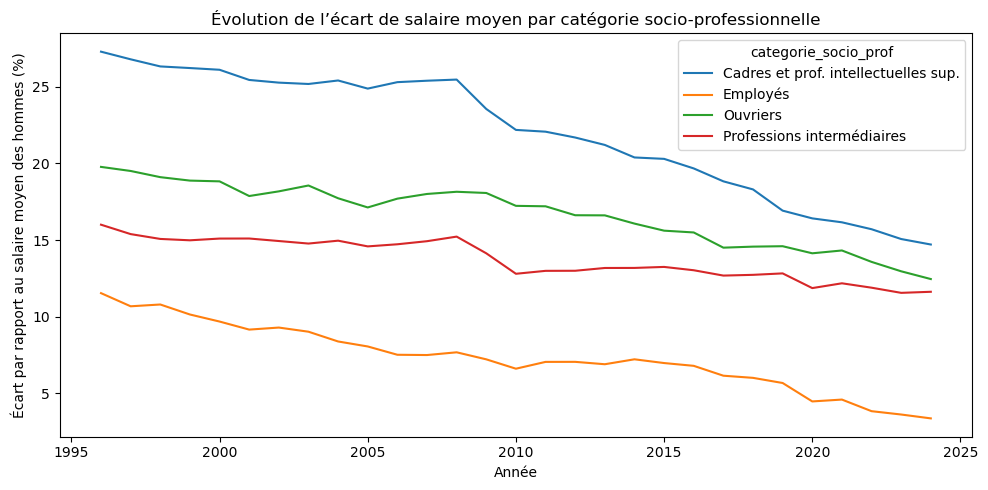

,Début (%),Fin (%),Évolution (points)
categorie_socio_prof,,,
Cadres et prof. intellectuelles sup.,27.3%,14.7%,-12.6
Employés,11.5%,3.4%,-8.2
Ouvriers,19.8%,12.5%,-7.3
Professions intermédiaires,16.0%,11.6%,-4.4


In [4]:
salaires_socioprof = prive[
    prive['indicateur'].eq(SALAIRE)
    & prive['unite'].eq('Euros constants')
    & prive['centile_salaire'].eq(MOYENNE)
    & prive['secteur_activite'].eq('Ensemble des secteurs')
    & prive['tranche_age'].eq('Ensemble')
    & prive['taille_entreprise'].eq('Ensemble')
    & prive['temps_travail'].eq('Ensemble')
    & prive['categorie_socio_prof'].ne('Ensemble')
    & prive['sexe'].isin(['Homme', 'Femme'])
].copy()
salaires_socioprof_pivot = salaires_socioprof.pivot(
    index=['annee', 'categorie_socio_prof'], columns='sexe', values='valeur'
).dropna(subset=['Homme', 'Femme'])
salaires_socioprof_pivot['Écart H-F (%)'] = (
    (salaires_socioprof_pivot['Homme'] - salaires_socioprof_pivot['Femme'])
    / salaires_socioprof_pivot['Homme']
    * 100
)
ecarts_socioprof = salaires_socioprof_pivot['Écart H-F (%)'].unstack(
    'categorie_socio_prof'
)

categories_attendues = {
    'Cadres et prof. intellectuelles sup.',
    'Professions intermédiaires',
    'Employés',
    'Ouvriers',
}
if set(ecarts_socioprof.columns) != categories_attendues:
    raise ValueError(
        'Catégories socio-professionnelles absentes : '
        f'{sorted(categories_attendues - set(ecarts_socioprof.columns))}'
    )

display(ecarts_socioprof.tail(10).style.format('{:.1f}%'))
ecarts_socioprof.plot(figsize=(10, 5))
plt.title('Évolution de l’écart de salaire moyen par catégorie socio-professionnelle')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()

resume_ecarts_socioprof = pd.DataFrame(
    {
        'Début (%)': ecarts_socioprof.iloc[0],
        'Fin (%)': ecarts_socioprof.iloc[-1],
        'Évolution (points)': ecarts_socioprof.iloc[-1] - ecarts_socioprof.iloc[0],
    }
)
display(
    resume_ecarts_socioprof.style.format(
        {'Début (%)': '{:.1f}%', 'Fin (%)': '{:.1f}%', 'Évolution (points)': '{:+.1f}'}
    )
)

## 4. Ratio P90/P10 selon le sexe

Pour chaque sexe, on divise le salaire au 90e centile par celui du 10e. Un ratio de 3 signifie que le P90 est trois fois le P10. C’est un indicateur simple de dispersion, pas une mesure complète des inégalités.

On trace l’évolution des deux ratios et on les compare sur les mêmes années.

sexe,Femme,Homme
annee,,
2015,2.63,3.14
2016,2.64,3.16
2017,2.66,3.15
2018,2.68,3.17
2019,2.68,3.14
2020,2.77,3.24
2021,2.72,3.17
2022,2.69,3.13
2023,2.65,3.08


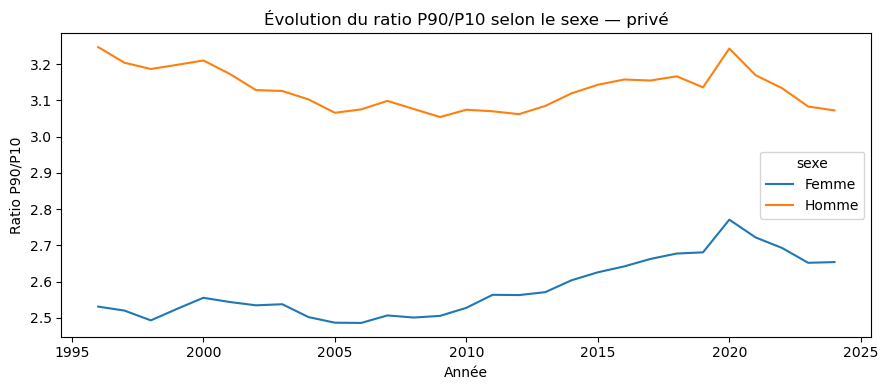

Période commune : 1996–2024. En 2024, le ratio est 3.07 pour les hommes et 2.65 pour les femmes.


In [5]:
def calculer_ratio_90_10(df, dimension=None):
    table = extraire_salaire(df, [P10, P90], dimension)
    index = ['annee'] if dimension is None else [dimension, 'annee']
    large = table.pivot(index=index, columns='centile_salaire', values='valeur')
    large = large.dropna(subset=[P10, P90]).copy()
    large['Ratio P90/P10'] = large[P90] / large[P10]
    return large.reset_index()


ratios_sexe = calculer_ratio_90_10(prive, 'sexe')
ratios_sexe = ratios_sexe[ratios_sexe['sexe'].isin(['Homme', 'Femme'])]
pivot_ratios_sexe = ratios_sexe.pivot(
    index='annee', columns='sexe', values='Ratio P90/P10'
).dropna(subset=['Homme', 'Femme'])

display(pivot_ratios_sexe.tail(10).style.format('{:.2f}'))
pivot_ratios_sexe.plot(figsize=(9, 4))
plt.title('Évolution du ratio P90/P10 selon le sexe — privé')
plt.xlabel('Année')
plt.ylabel('Ratio P90/P10')
plt.tight_layout()
plt.show()

print(
    f"Période commune : {pivot_ratios_sexe.index.min()}–{pivot_ratios_sexe.index.max()}. "
    f"En {pivot_ratios_sexe.index.max()}, le ratio est "
    f"{pivot_ratios_sexe['Homme'].iloc[-1]:.2f} pour les hommes et "
    f"{pivot_ratios_sexe['Femme'].iloc[-1]:.2f} pour les femmes."
)

## 5. Comparaison des P90 hommes et femmes

On compare **P90 homme / P90 femme** au fil du temps. Un ratio de 1 signifie que les deux P90 sont égaux; au-dessus de 1, le P90 des hommes est plus élevé.

sexe,Homme,Femme,Ratio P90 homme/femme
annee,,,
2015,"4,683","3,692",1.268
2016,"4,692","3,728",1.259
2017,"4,710","3,797",1.240
2018,"4,721","3,829",1.233
2019,"4,729","3,890",1.216
2020,"4,913","4,054",1.212
2021,"4,773","3,966",1.203
2022,"4,685","3,924",1.194
2023,"4,609","3,880",1.188


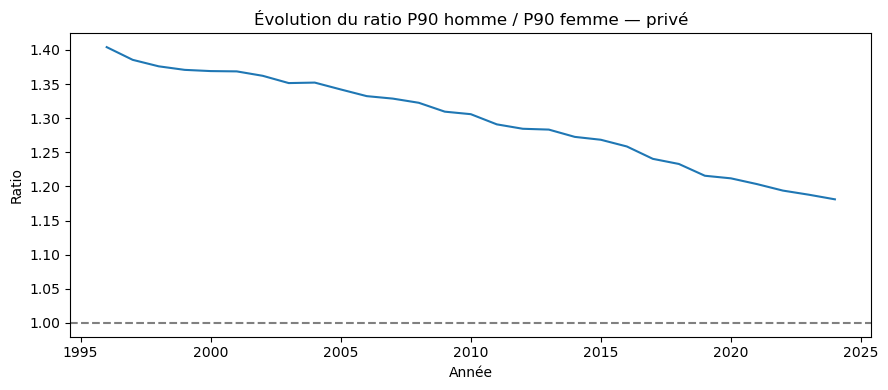

Le ratio passe de 1.404 en 1996 à 1.181 en 2024.


In [6]:
p90_sexe = extraire_salaire(prive, [P90], 'sexe')
pivot_p90_sexe = p90_sexe.pivot(
    index='annee', columns='sexe', values='valeur'
).dropna(subset=['Homme', 'Femme'])
pivot_p90_sexe['Ratio P90 homme/femme'] = (
    pivot_p90_sexe['Homme'] / pivot_p90_sexe['Femme']
)

display(
    pivot_p90_sexe[['Homme', 'Femme', 'Ratio P90 homme/femme']]
    .tail(10)
    .style.format({'Homme': '{:,.0f}', 'Femme': '{:,.0f}', 'Ratio P90 homme/femme': '{:.3f}'})
)
pivot_p90_sexe['Ratio P90 homme/femme'].plot(figsize=(9, 4))
plt.axhline(1, color='gray', linestyle='--')
plt.title('Évolution du ratio P90 homme / P90 femme — privé')
plt.xlabel('Année')
plt.ylabel('Ratio')
plt.tight_layout()
plt.show()

print(
    f"Le ratio passe de {pivot_p90_sexe['Ratio P90 homme/femme'].iloc[0]:.3f} "
    f"en {pivot_p90_sexe.index.min()} à "
    f"{pivot_p90_sexe['Ratio P90 homme/femme'].iloc[-1]:.3f} "
    f"en {pivot_p90_sexe.index.max()}."
)

### Quelle part de la masse salariale va aux plus hauts revenus ?

Le fichier privé contient aussi la part de la masse salariale reçue par les 10 %, 1 %, 0,1 % et 0,01 % les mieux rémunérés. C’est un autre indicateur que P90/P10 : on suit ici une **part en pourcentage**, pas un salaire.

Groupe,"top 0,01%","top 0,1%",top 1%,top 10%
annee,,,,
2015,0.64%,2.13%,7.43%,28.74%
2016,0.70%,2.17%,7.45%,29.07%
2017,0.61%,2.09%,7.40%,29.00%
2018,0.58%,2.09%,7.43%,29.04%
2019,0.53%,1.90%,7.02%,28.36%
2020,0.57%,1.96%,7.20%,29.10%
2021,0.56%,1.96%,7.12%,28.56%
2022,0.60%,1.97%,7.01%,28.15%
2023,0.57%,1.90%,6.85%,27.72%


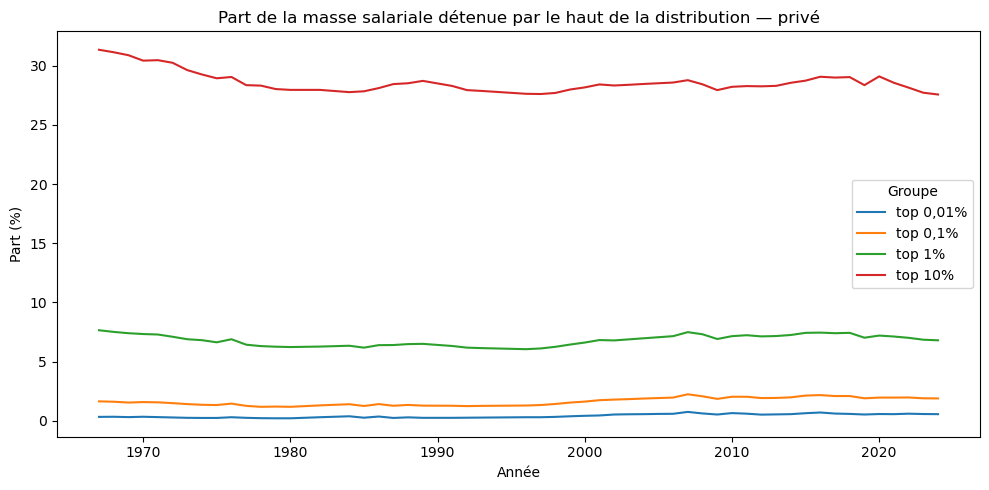

In [7]:
part_top = garder_ensemble_des_autres_dimensions(prive)
part_top = part_top[
    part_top['indicateur'].str.startswith('Part de la masse salariale perçue par le top ')
    & part_top['centile_salaire'].eq('Ensemble')
].copy()
part_top['Groupe'] = part_top['indicateur'].str.extract(r'(top .+)$', expand=False)
part_top = part_top.pivot(index='annee', columns='Groupe', values='valeur')
display(part_top.tail(10).style.format('{:.2f}%'))
part_top.plot(figsize=(10, 5))
plt.title('Part de la masse salariale détenue par le haut de la distribution — privé')
plt.xlabel('Année')
plt.ylabel('Part (%)')
plt.tight_layout()
plt.show()

## 6. Et du côté des salaires les plus bas ?

On suit P10 et P25 avec la médiane comme repère. Comme pour les salaires du haut, on compare les euros constants et on affiche les dates réellement disponibles.

Série,Médiane,P10,P25
annee,,,
2015,"2,120","1,444","1,688"
2016,"2,129","1,447","1,691"
2017,"2,147","1,458","1,702"
2018,"2,150","1,459","1,705"
2019,"2,204","1,478","1,741"
2020,"2,258","1,489","1,772"
2021,"2,220","1,480","1,747"
2022,"2,185","1,475","1,731"
2023,"2,173","1,478","1,731"


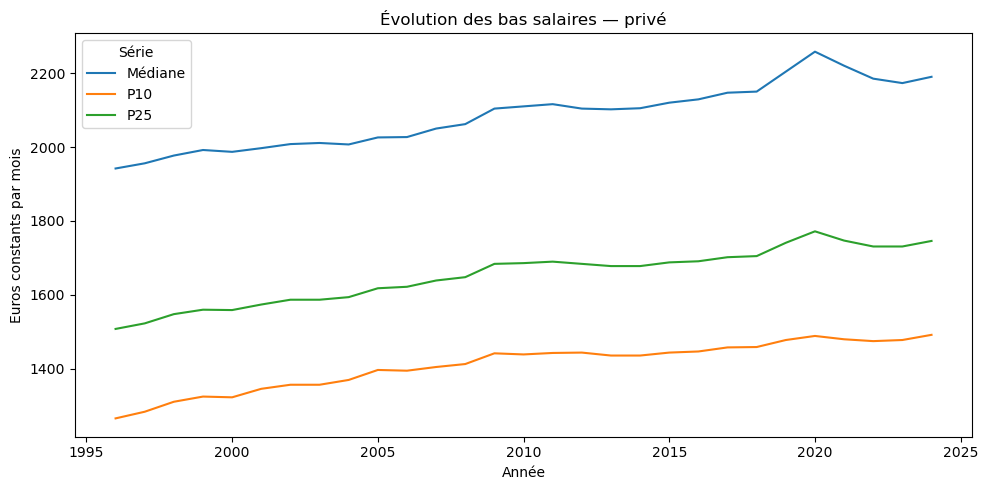

,Période,Variation (%)
Série,,
Médiane,1996–2024,+12.8%
P10,1996–2024,+17.9%
P25,1996–2024,+15.8%


In [8]:
series_bas = pd.concat(
    [
        serie_quantile(prive, P10, 'P10'),
        serie_quantile(prive, P25, 'P25'),
        serie_quantile(prive, P50, 'Médiane'),
    ],
    ignore_index=True,
)

pivot_bas = series_bas.pivot(index='annee', columns='Série', values='Salaire (€ constants)')
display(pivot_bas.tail(10).style.format('{:,.0f}'))
pivot_bas.plot(figsize=(10, 5))
plt.title('Évolution des bas salaires — privé')
plt.xlabel('Année')
plt.ylabel('Euros constants par mois')
plt.tight_layout()
plt.show()

display(bilan_evolution(series_bas).style.format({'Début (€)': '{:,.0f}', 'Fin (€)': '{:,.0f}', 'Variation (%)': '{:+.1f}%'}))

## À garder en tête

- Les quantiles P10 et P90 ne sont pas détaillés par secteur ni par taille d’entreprise, donc on ne peut pas calculer les ratios d’inégalité pour ces groupes.
- Les périodes ne sont pas toujours les mêmes et certaines années peuvent manquer. Les tableaux d’évolution indiquent les années de début et de fin effectivement observées.
- Le ratio P90/P10 résume un écart entre deux points de la distribution; il ne raconte pas toute l’histoire des inégalités.
- Ces données décrivent des salaires mensuels en équivalent temps plein (EQTP); elles ne mesurent pas directement le revenu annuel ou le niveau de vie.